# Cymbal Audio Analysis

We're going to examine a raw wav audio file containing individual cymbal strikes at 20 a piece in three different locations, for a total of 60 separate strikes. The objective is to investigate how the location at which a cymbal is struck affects the frequency characteristics of the resulting sound. We'll be using Numpy to handle our array and numerical operations, SciPy to read in the WAV file, for its Fast Fourier Transform tools, and other helpful wave tools, and Matplotlib to plot our results and gain a visual understanding of our findings. 

In [50]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
from scipy.signal import find_peaks

## Loading the Raw Audio Data

We're importing the raw WAV file into Python using SciPy. The recording was sampled at 48,000 samples per second and contains a single audio channel. 

In [51]:
sample_rate, audio = wavfile.read('cymbal_analysis_raw.wav')

In [52]:
print('Sample rate:', sample_rate)
print('Audio shape:', audio.shape)
print('Data type:', audio.dtype)

Sample rate: 48000
Audio shape: (38461440,)
Data type: int16


## Plotting the Whole Audio File

Plotting the entire WAV file here. Just want to get a feel for what we're working with before splitting this up.

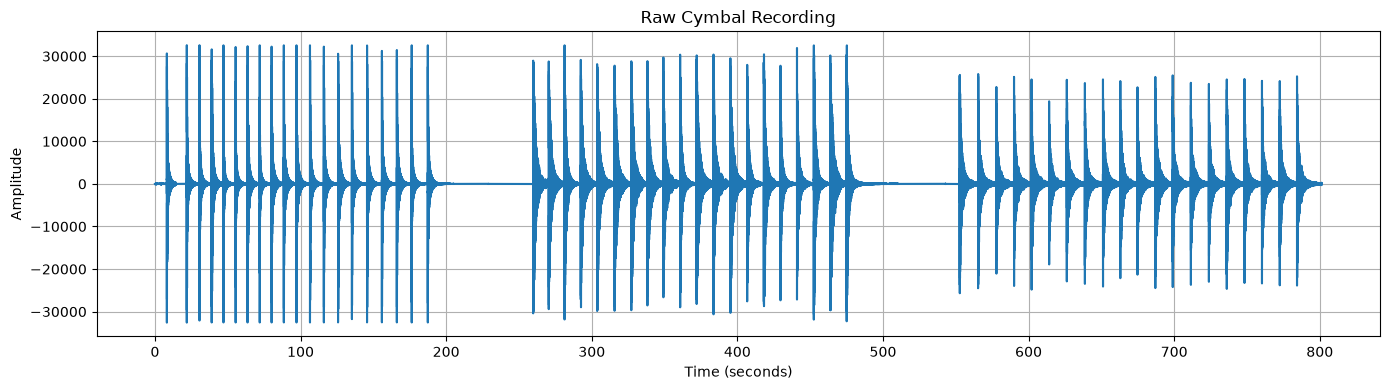

In [53]:
time = np.arange(len(audio))/sample_rate

plt.figure(figsize=(14, 4))
plt.plot(time, audio)
plt.xlabel('Time (seconds)')
plt.ylabel('Amplitude')
plt.title('Raw Cymbal Recording')
plt.grid(True)
plt.tight_layout()
plt.show()

## Separating the Recording into Experimental Groups

As shown above, the full recording contains three sections corresponding to three strike locations. Separate plots will now be used to examine the timing and consistency of the recorded strikes within each group.

The time ranges used initially are approximate and will be refined by inspecting the plots. To make the individual strikes more easily distinguished, the signal is summarized using RMS amplitude in short time windows. The purpose here is to reduce the amount of data displayed without modifying the original recording.

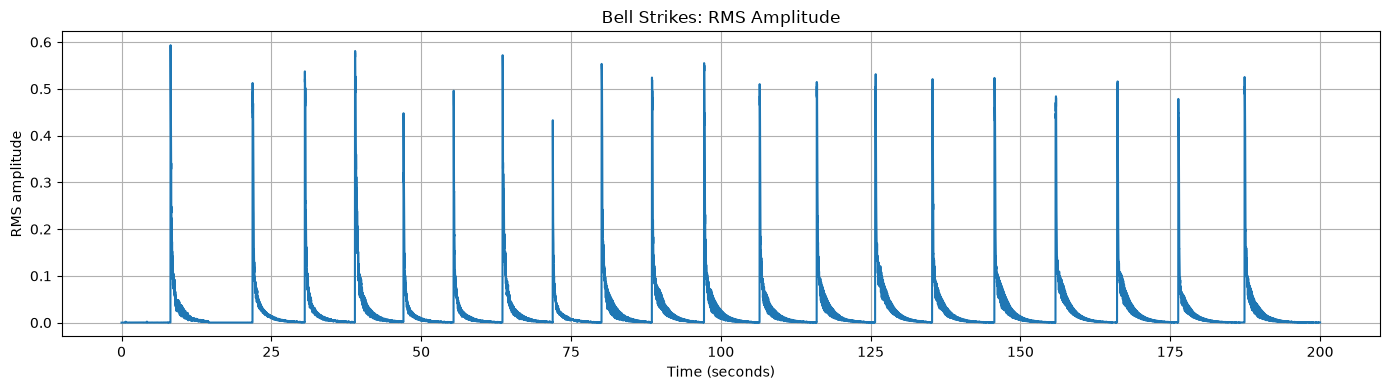

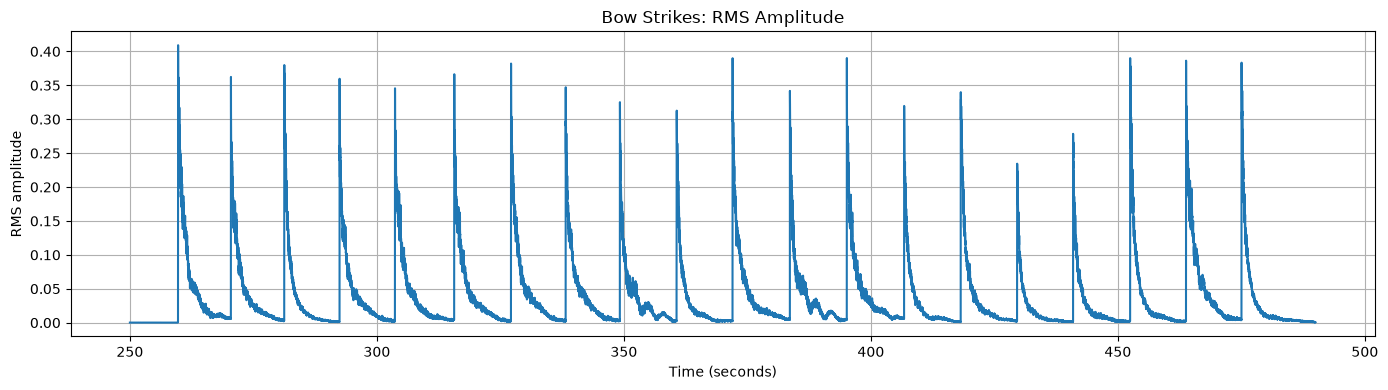

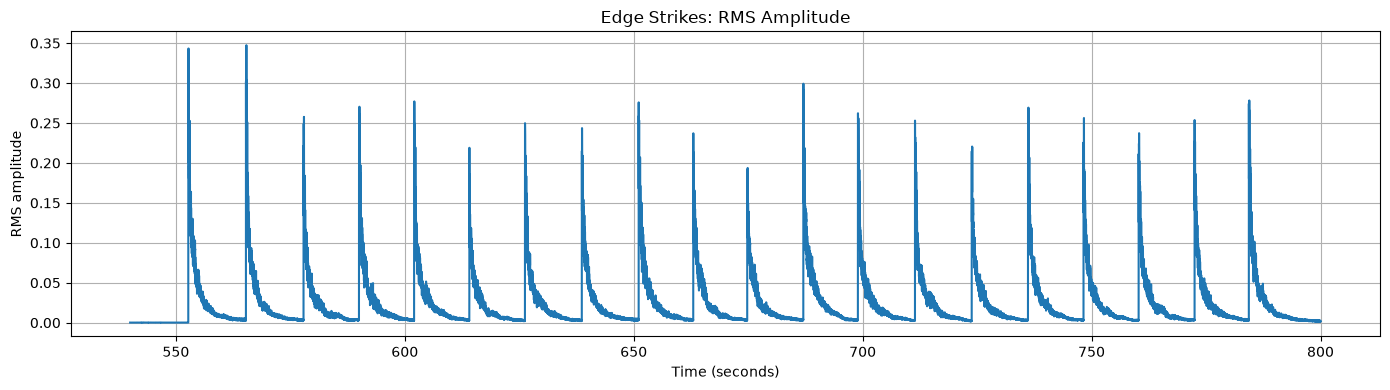

In [54]:
# I need to convert the integer audio samples to floating point values that are within the range of -1 to 1.
# The type shown in cell 3 of int16 indicates a range of -32,768 to 32,767, so we need to divide by the upper value.
audio_float = audio.astype(np.float64) / 32768.0

# Using approximate ranges here based on the graph above. 
groups = {'Bell': (0, 200), 'Bow': (250, 490), 'Edge': (540, 800)}

# Now to calculate the Root Mean Square (RMS) amplitude. Using a 10 millisecond window seems reasonable for
# us to gather groupings of 48,000 * 0.01 = 480 samples to work with.
window_size = int(0.01*sample_rate)

# Storing each envelope to determine exact onset time as needed for the next step.
rms_envelopes = {}

for name, (start_time, end_time) in groups.items():
    start_index = int(start_time*sample_rate)
    end_index = int(end_time*sample_rate)
    segment = audio_float[start_index:end_index]

    # Now let's divide these into equal sized windows.
    usable_length = (len(segment)//window_size)*window_size
    windows = segment[:usable_length].reshape(-1, window_size)

    # RMS will measure the signal's strength within each window.
    rms = np.sqrt(np.mean(windows**2, axis=1))

    # Use the center of each window for its time coordinate.
    times = (start_time + (np.arange(len(rms)) + 0.5)*window_size/sample_rate)

    rms_envelopes[name] = {'times': times, 'rms': rms}

    # Finally, to plot the RMS for this grouping.
    plt.figure(figsize=(14, 4))
    plt.plot(times, rms)
    plt.xlabel('Time (seconds)')
    plt.ylabel('RMS amplitude')
    plt.title(f'{name} Strikes: RMS Amplitude')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

## Quick Stop Analysis

The three graphs above appear consistent with expectations. The bell strikes look to decay quickly, the bow less so, and the edge hits decay the least quickly.

## Identifying Individual Cymbal Strikes

Before we perform the Fourier analysis, each cymbal strike must be identified and isolated from the continuous recording. We'll need to determine the exact onset time and duration of each strike. We'll be using the assistance of SciPy's find_peaks function here.

The RMS amplitude envelopes provide a useful overview of the recording, however, the onset times should be determined more precisely before extracting individual audio segements. Once the individual strikes have been identified, their timing information can be used to extract the corresponding samples from the original audio recording. The extracted segments will then serve as the input for the Fast Fourier Transform (FFT), which will be used to examine the frequency characteristics of each strike.

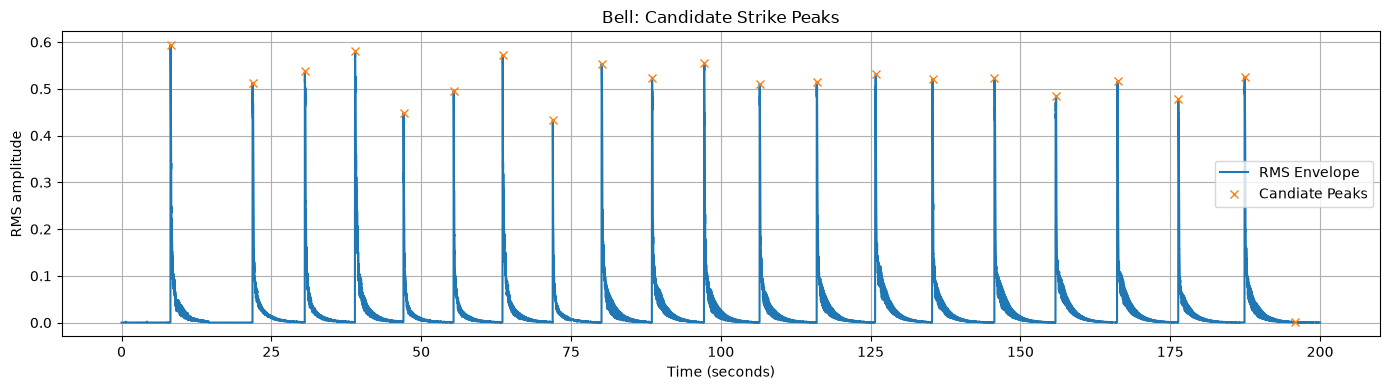

Bell: 21 candidate peaks
Candidate times (seconds):
[  8.18  21.88  30.6   38.98  47.06  55.42  63.6   71.96  80.11  88.52
  97.22 106.48 116.02 125.84 135.34 145.66 155.93 166.22 176.34 187.4
 195.74]



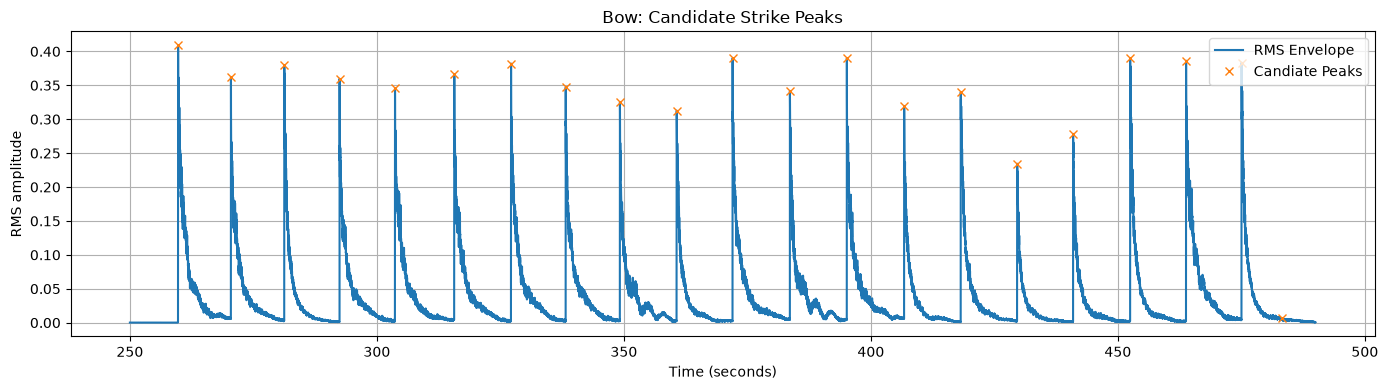

Bow: 21 candidate peaks
Candidate times (seconds):
[259.76 270.46 281.26 292.46 303.68 315.68 327.17 338.24 349.2  360.7
 372.02 383.62 395.14 406.74 418.21 429.62 440.94 452.5  463.82 475.04
 483.18]



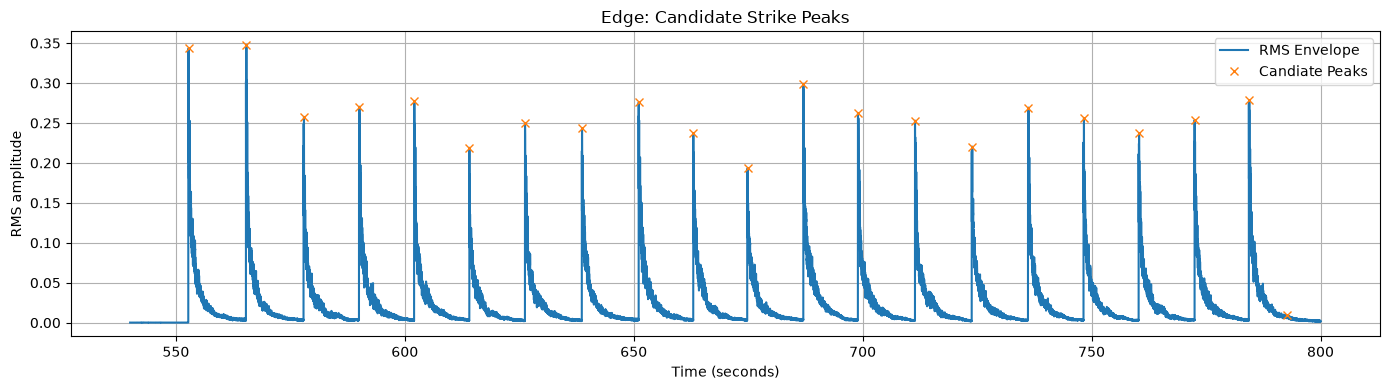

Edge: 21 candidate peaks
Candidate times (seconds):
[552.76 565.4  577.98 590.08 602.08 614.1  626.26 638.71 651.08 663.02
 674.88 687.06 698.98 711.44 723.9  736.2  748.34 760.38 772.5  784.44
 792.58]



In [55]:
# Finding the individual strike onsets.
min_separation = 8.0

verified_peak_times = {}

# Using the rms evelope items created in cell 8.
for name, data in rms_envelopes.items():
    times = data['times']
    rms = data['rms']

    # We need a min distance passed in to the find_peaks function or we get flooded with potential candidates.
    min_distance = int(min_separation/0.01)

    peaks, properties = find_peaks(rms, distance=min_distance, prominence=0.0005)

    candidate_times = times[peaks]

    # Graphs below will show that the last value can be discarded for purposes of finding the actual peaks.
    # See md cell Selected Strike Event Verification below for further clarification as needed.
    verified_peak_times[name] = candidate_times[:20]

    plt.figure(figsize=(14, 4))
    plt.plot(times, rms, label='RMS Envelope')
    plt.plot(times[peaks], rms[peaks], 'x', label='Candiate Peaks')

    plt.xlabel('Time (seconds)')
    plt.ylabel('RMS amplitude')
    plt.title(f'{name}: Candidate Strike Peaks')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    print(f'{name}: {len(peaks)} candidate peaks')
    print('Candidate times (seconds):')
    print(np.round(times[peaks], 2))
    print()

## Detected Strike Event Verification

The detector identified 21 candidate peaks in each experimental group, although the experiment consisted of 20 strikes per location. Visual inspection of the RMS plots showed that the final candidate in each group occurred during the decay of the final strike rather than representing a separate strike. Based on this inspection and the known experimental design, the final candidate was excluded from each group's list of detected events that are now properly stored in verified_peak_times.


## Extracting Individual Strike Events

The detected RMS peak times provide reference points for individual cymbal strikes. However, the time of maximum RMS amplitude does not necessarily correspond to the initial impact. Before extracting audio segments, the relationship between each peak and the onset of the strike must be examined.

A consistent segment selection method is important because differences in segment alignment or duration could affect comparisons of frequency content and sound decay across strike locations.

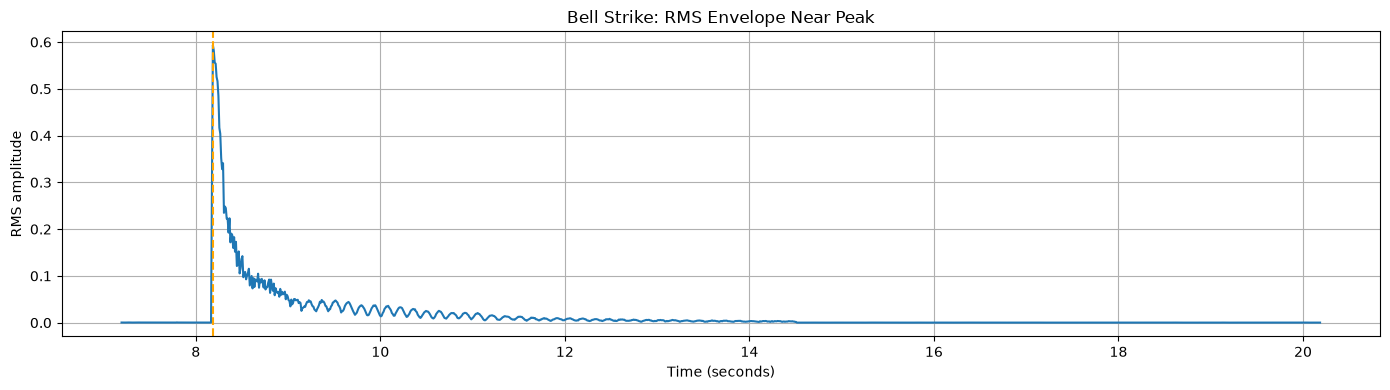

In [56]:
name = 'Bell'
peak_time = verified_peak_times[name][0]

data = rms_envelopes[name]
times = data['times']
rms = data['rms']

# Numpy arrays use the & symbol. Tricky tricky.
mask = (times >= peak_time - 1.0) & (times <= peak_time + 12.0)

plt.figure(figsize=(14, 4))
plt.plot(times[mask], rms[mask])
plt.axvline(peak_time, color='orange', linestyle='--', label='RMS peak')
plt.xlabel('Time (seconds)')
plt.ylabel('RMS amplitude')
plt.title(f'{name} Strike: RMS Envelope Near Peak')
plt.grid(True)
plt.tight_layout()
plt.show()

In [57]:
# Quick search for the minimum distance between peaks.
minimum_distance = float('inf')
for time in verified_peak_times.values():
    for i in range(len(time) - 1):
        if time[i+1] - time[i] < minimum_distance:
            minimum_distance = time[i+1] - time[i]
print(minimum_distance)

8.07


## Separating Strike Events

Switching between the different strike locations and examining different strikes within each location using the graph in cell 15 (RMS Envelope Near Peak), we see that the peak occurs almost instantly after the strike occurs, and is decayed to a significant point after roughly 7.5 seconds at a max. Coupling this with the minimum distance between any two peaks found in the loop directly above, the decision is now made to use an 8 second audio segement for each strike. We will use a window of 0.5 seconds before the peak and 7.5 seconds after. While grabbing 0.5 seconds before the peak doesn't ensure that the previous strike has completely decayed, it does appear to have decayed enough to make it insignificant for our purposes. 

We're using a consistent duration here to allow the frequency characteristics and temporal decay of the three strike locations to be compared under the same analysis conditions. A similar pattern to what was used in cell 6 to separate the separate strike locations will be used here to further separate each strike.

In [58]:
time_before_peak = 0.5
time_after_peak = 7.5

# Converting the time intervals into numbers of audio samples
samples_before = int(time_before_peak*sample_rate)
samples_after = int(time_after_peak*sample_rate)

# Need a place to store the segments
segments = {}

# Now to loop through each location and time further within each location.
for name, peak_times in verified_peak_times.items():
    segments[name] = []

    for peak_time in peak_times:
        peak_index = int(round(peak_time*sample_rate))
        start_index = peak_index - samples_before
        end_index = peak_index + samples_after

        segment = audio_float[start_index:end_index]
        segments[name].append(segment)

print(f'Samples per segment: {samples_before + samples_after}')
print(f'Duration per segment: {(samples_before + samples_after)/sample_rate} seconds')

for name, group_segments in segments.items():
    print(f'{name}: {len(group_segments)} segments')

Samples per segment: 384000
Duration per segment: 8.0 seconds
Bell: 20 segments
Bow: 20 segments
Edge: 20 segments


## Inspecting an Individual Audio Segment

Before performing frequency analysis, let's take a look at an individual audio segment in the time domain. The segment contains the original recorded samples for one cymbal strike, beginning 0.5 seconds before its detected RMS peak and extending 7.5 seconds afterward. Inspecting the waveform provides a visual check of the selected interval and helps establish how the signla's amplitude changes over time. 

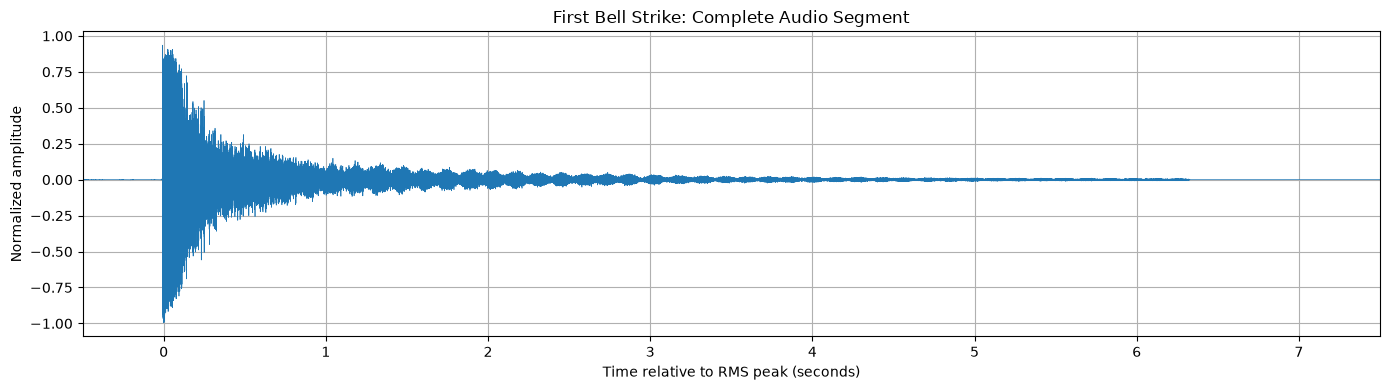

In [59]:
test_segment = segments['Bell'][0]

segment_time = np.arange(len(test_segment))/sample_rate - 0.5

plt.figure(figsize=(14, 4))
plt.plot(segment_time, test_segment, linewidth=0.5)
plt.xlabel('Time relative to RMS peak (seconds)')
plt.ylabel('Normalized amplitude')
plt.title('First Bell Strike: Complete Audio Segment')
plt.xlim(-0.5, 7.5)
plt.grid(True)
plt.tight_layout()
plt.show()

## Inspecting an Individual Audio Segment: Zoomed In

Let's examine this a little closer to impact. I just want to try and get a feel for the oscillations close to strike. 

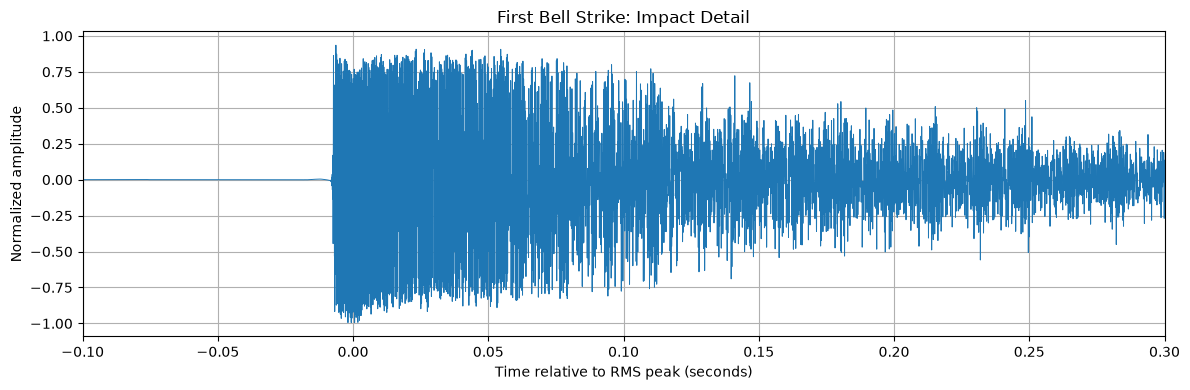

In [60]:
plt.figure(figsize=(12, 4))
plt.plot(segment_time, test_segment, linewidth=0.7)
plt.xlabel('Time relative to RMS peak (seconds)')
plt.ylabel('Normalized amplitude')
plt.title('First Bell Strike: Impact Detail')
plt.xlim(-0.1, 0.3)
plt.grid(True)
plt.tight_layout()
plt.show()

## Applying the Fast Fourier Transform

We're going to now use the Fast Fourier Transform (FFT) algorithm to calculate the Discrete Fourier Transform (DFT). The DFT represents a finite sequence of audio samples in terms of its frequency components. 

For the initial analysis, we'll look at the first bell strike, remove the segment's mean to reduce any constant offset, and apply a Hann window to reduce spectral leakage at the segment boundaries. The FFT is then calculated using SciPy. The magnitude of the FFT coefficients is used to examine the relative strength of the frequency components. A corresponding frequency axis is calculated using the recording's sampling rate of 48,000 Hz. After this initial calculation, we'll apply the same procedure to every strike.

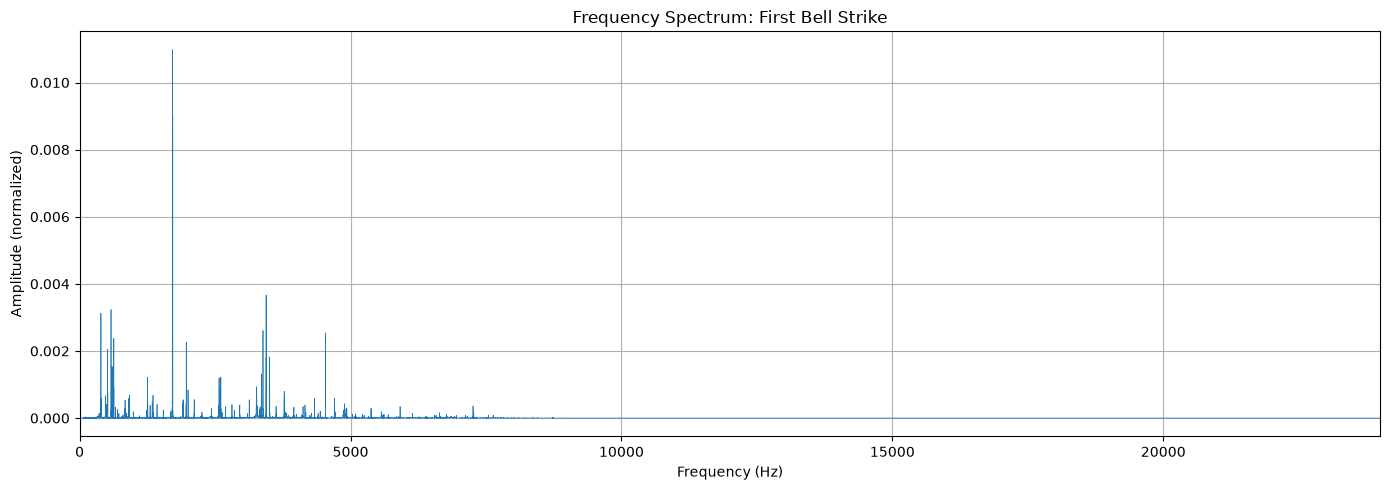

In [61]:
from scipy.fft import rfft, rfftfreq
from scipy.signal.windows import hann

# Using the first bell strike labeled as test_segment in cell 20 above and removing the constant mean.
centered_segment = test_segment - np.mean(test_segment)

window = hann(len(centered_segment), sym=False)
windowed_segment = centered_segment*window

# Now to calculate the FFT and corresponding frequencies
fft_values = rfft(windowed_segment)
frequencies = rfftfreq(len(windowed_segment), d=1/sample_rate)

# Gathering the magnitude of each complex FFT coefficient and refining out the non-complex portion. 
amplitude = np.abs(fft_values)/np.sum(window)
amplitude[1:-1] *= 2

# We need to account for neagtive frequency components ommitted by rfft. We don't touch the DC component at index 0, or the Nyquist component at index -1. 

# Let's plot the spectrum
plt.figure(figsize=(14, 5))
plt.plot(frequencies, amplitude, linewidth=0.5)
plt.xlabel('Frequency (Hz)')
plt.ylabel('Amplitude (normalized)')
plt.title('Frequency Spectrum: First Bell Strike')
plt.xlim(0, sample_rate/2)
plt.grid(True)
plt.tight_layout()
plt.show()


## Processing Every Strike

The initial Fourier transform was performed on one bell strike to establish and verify the processing proceduce. Now we're to apply that same procedure to all 60 extracted audio segments using the same techniques demonstrated in cell 24 above.

In [62]:
spectra = {}
frequencies = None

for location, location_segments in segments.items():
    spectra[location] = []

    for segment in location_segments:
        centered_segment = segment - np.mean(segment)

        window = hann(len(centered_segment), sym=False)
        windowed_segment = centered_segment*window

        fft_values = rfft(windowed_segment)

        amplitude = np.abs(fft_values)/np.sum(window)
        amplitude[1:-1] *= 2

        if frequencies is None:
            frequencies = rfftfreq(len(windowed_segment), d=1/sample_rate)

        spectra[location].append(amplitude)

# Converting each location's list of spectra into NumPy arrays.
for location in spectra:
    spectra[location] = np.array(spectra[location])

# Now let's verify what we've done is correct.
print(f'Number of frequency bins: {len(frequencies)}')

for location, location_spectra in spectra.items():
    print(f'{location}: {location_spectra.shape[0]} strikes, {location_spectra.shape[1]} frequency bins')

Number of frequency bins: 192001
Bell: 20 strikes, 192001 frequency bins
Bow: 20 strikes, 192001 frequency bins
Edge: 20 strikes, 192001 frequency bins


The output matches our expectations. Each spectrum contains 192,001 frequency bins because the real valued FFT of 384,000 samples returns (N/2 + 1) frequency components, including both 0 Hz and the 24,000 Hz Nyquist frequency.

## Calculating Mean Spectra and Standard Deviations

Now we finally get to the mean spectra and std calculations. The mean spectrum represents the average frequency content, while the standard deviation measures how much the amplitude varies between strikes at each frequency. NumPy is going to make easy work of most of this. To note, we're ussing ddof=1 which applies the sample standard deviation formula to account for the fact that these trials represent repeated measurements rather than the entire population.

In [63]:
mean_spectra = {}
std_spectra = {}

for location, location_spectra in spectra.items():
    mean_spectra[location] = np.mean(location_spectra, axis=0)
    std_spectra[location] = np.std(location_spectra, axis=0, ddof=1)

# Just want to keep verifying along the way.
for location in spectra:
    print(f'{location}: {len(mean_spectra[location])} mean values, {len(std_spectra[location])} standard deviations')

Bell: 192001 mean values, 192001 standard deviations
Bow: 192001 mean values, 192001 standard deviations
Edge: 192001 mean values, 192001 standard deviations


## Compare the Mean Frequency Spectra

Let's now compare the mean amplitude spectra for the bell, bow, and edge by plotting on the same graph over the 0 - 7,500 Hz range. Using a shared frequency axis allows us to compare the average frequency content of each strike location and identify differences in prominent frequency components. 

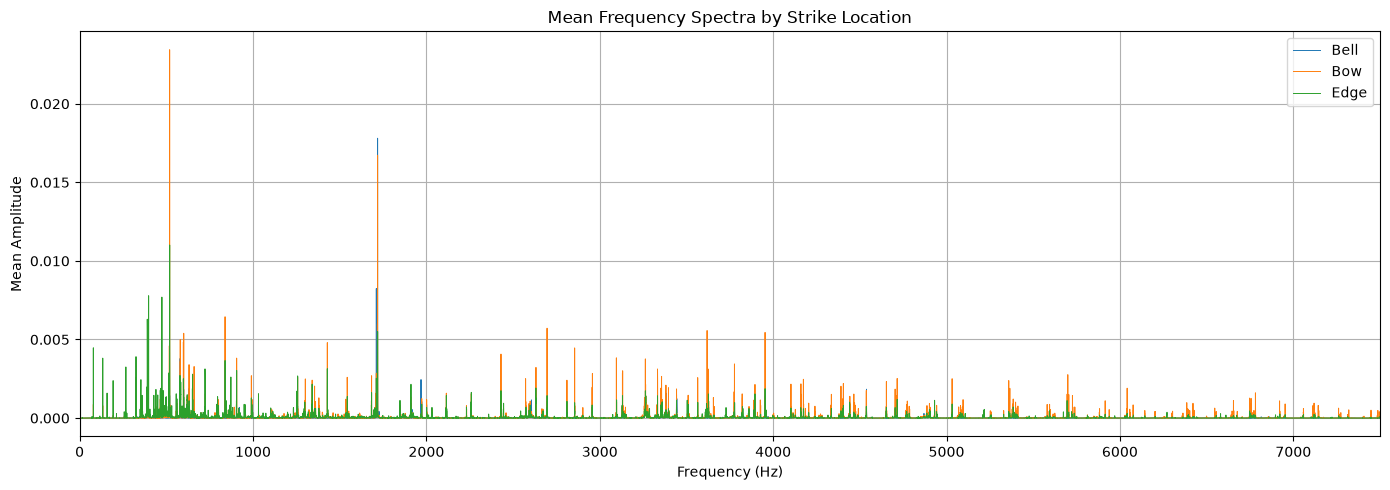

In [64]:
plt.figure(figsize=(14, 5))

for location, mean_amplitude in mean_spectra.items():
    plt.plot(frequencies, mean_amplitude, label=location, linewidth=0.7)

plt.xlabel('Frequency (Hz)')
plt.ylabel('Mean Amplitude')
plt.title('Mean Frequency Spectra by Strike Location')
plt.xlim(0, 7500)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Going to resolve this overlap by providing each location with its own subplot.

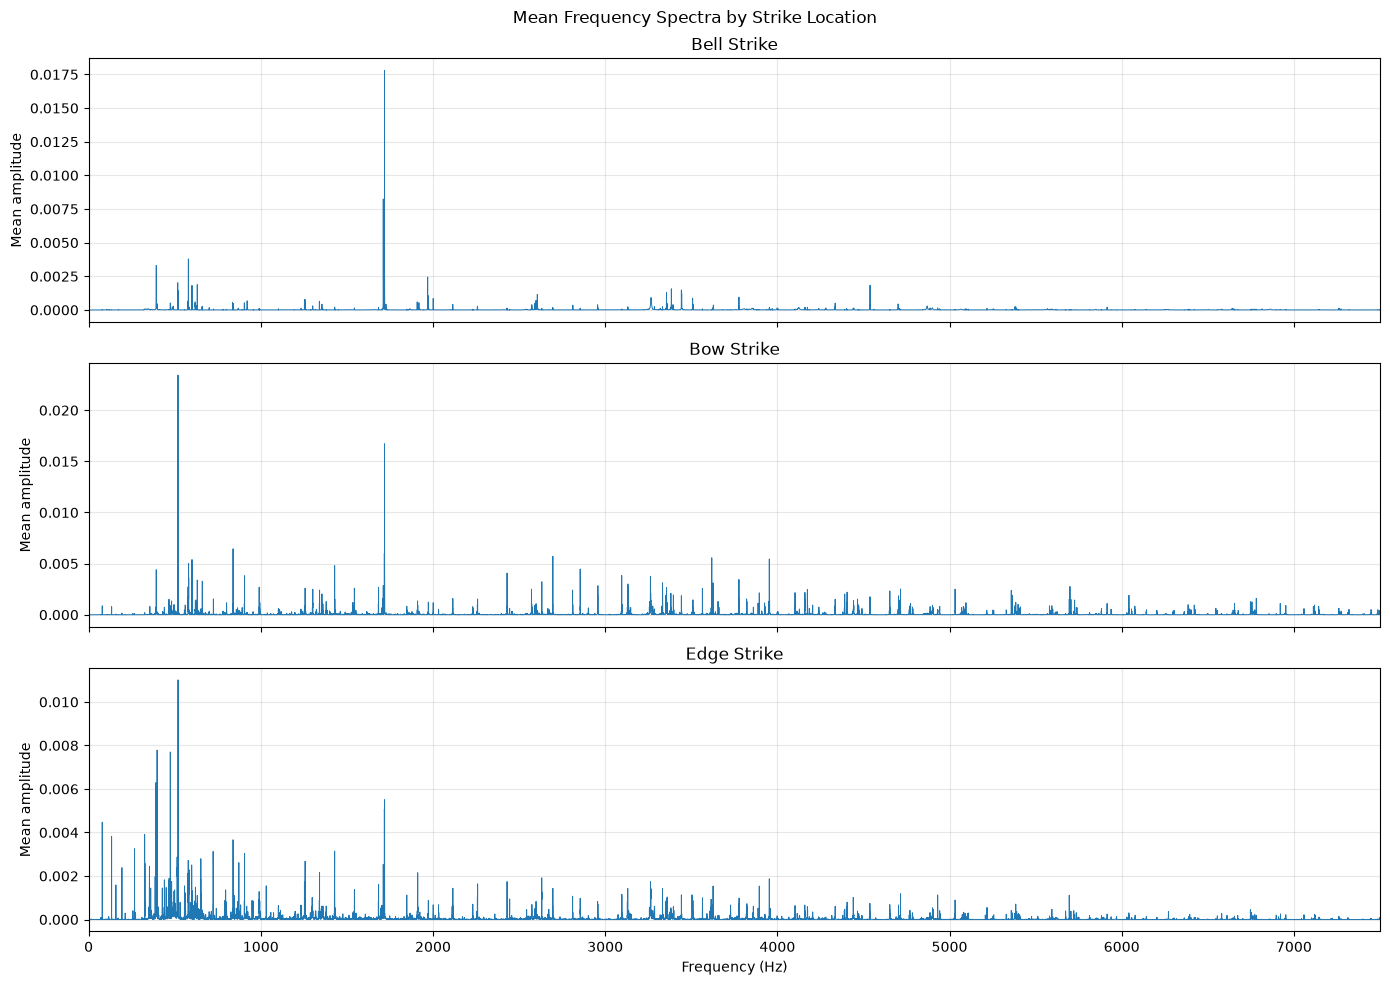

In [65]:
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

for ax, location in zip(axes, ['Bell', 'Bow', 'Edge']):
    ax.plot(frequencies, mean_spectra[location], linewidth=0.7)
    ax.set_ylabel('Mean amplitude')
    ax.set_title(f'{location} Strike')
    ax.set_xlim(0, 7500)
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel('Frequency (Hz)')

fig.suptitle('Mean Frequency Spectra by Strike Location')
fig.tight_layout()
plt.show()

## Initial Observations of Mean Frequency Spectra

The mean spectra show apparent differences in frequency content across the three strike locations. The bell strikes exhibit a prominent peak near 1,750 Hz, with an amplitude of approximately 0.0175, but relatively few other prominent peaks. The bow strikes show a strong peak near 500 Hz at approimxately 0.025, along with a secondary peak near 1,750 Hz at approximately 0.016. The edge strikes also exhibit a prominent peak near 500 Hz, at approximately 0.011, accompanied by several small peaks below 1,000 Hz.

Across all three locations, additional peaks occur at higher frequencies, generally with lower amplitudes. These observations suggest that strike location influences the distribution of frequency amplitudes, although the consistency of these features across individual trials must be considered before drawing firm conclusions. 

Next, let's visualize the standard deviation spectra.

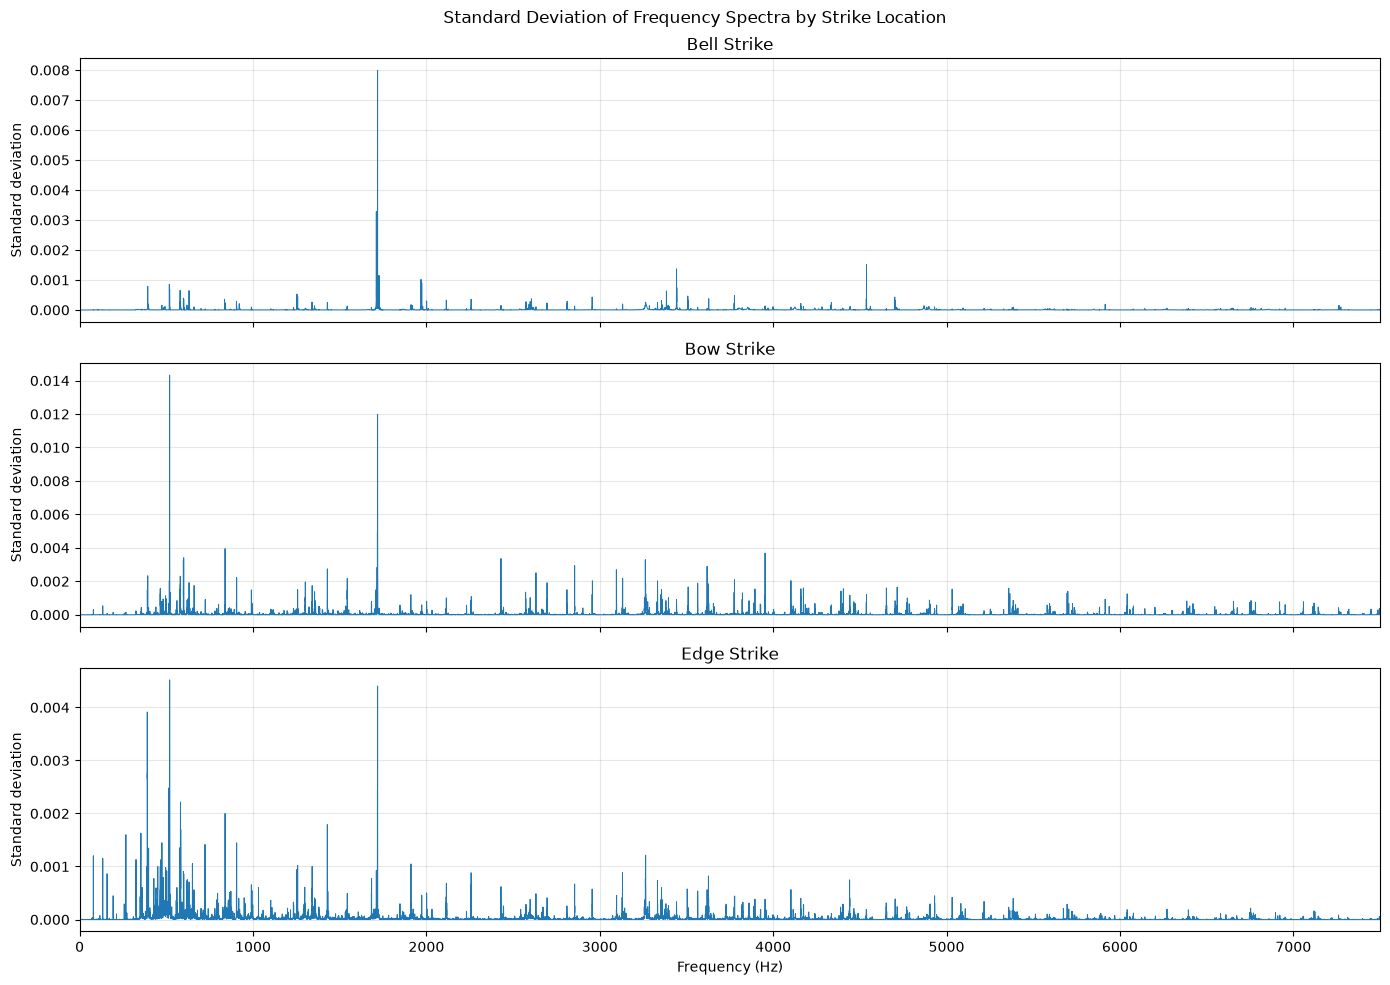

In [66]:
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

for ax, location in zip(axes, ['Bell', 'Bow', 'Edge']):
    ax.plot(frequencies, std_spectra[location], linewidth=0.7)
    ax.set_ylabel('Standard deviation')
    ax.set_title(f'{location} Strike')
    ax.set_xlim(0, 7500)
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel('Frequency (Hz)')

fig.suptitle('Standard Deviation of Frequency Spectra by Strike Location')
fig.tight_layout()
plt.show()

## Observations of Standard Deviation Spectra

The standard deviation spectra show prominent peaks in frequency regions similar to those observed in the mean spectra. The bell strikes have a maximum standard deviation of approximately 0.008 near 1,750 Hz, while the bow strikes reach approximately 0.014 at around 500 Hz. The edge strikes show peaks of approximately 0.005 near 500 Hz and 1,750 Hz, with another slightly smaller peak near 400 Hz at approimxately 0.004.

These results indicate that trial to trial variability differs across strike locations and is concentrated in several of the same frequency regions that exhibit prominent mean amplitudes. Further quantitative comparison will help determine how consistently the observed frequency characteristics distinguish the three locations and we'll do this by next comparing the strikes across separate frequency bands.

## Quantitative Comparison of Frequency Bands

Let's now divide the frequency spectrum into three broad bands: low (0-1,000 Hz), mid (1,000-3,000 Hz), and high (3,000-7,500 Hz). For each strike, we'll sum the squared amplitudes within each band to obtain a relative spectral energy measure. Then, the mean and sample standard deviation of this measure are calculated across the 20 trials for each strike location. These summaries should provide a quantitative comparison of how the recorded frequency content varies by location and how consistent those measurements are across repeated strikes.

In [67]:
# First to define the frequency bands.
bands = {'Low (0-1000 Hz)': (0, 1000), 'Mid (1000-3000 Hz)': (1000, 3000), 'High (3000-7500 Hz)': (3000, 7500)}

band_values = {}

for location, location_spectra in spectra.items():
    band_values[location] = {}

    for band_name, (low, high) in bands.items():
        # Selecting frequency bins within the band using mask in a similar to way we did in cell 15. 
        mask = (frequencies >= low) & (frequencies < high)

        # Now to sum the squared amplitudes for each strike
        values = np.sum(location_spectra[:, mask]**2, axis=1)
        band_values[location][band_name] = values

# Calculating the mean and sample standard deviation across strikes.
print('Mean and standard deviation by location and frequency band')

for location in band_values:
    print(location)

    for band_name in bands:
        values = band_values[location][band_name]

        mean_value = np.mean(values)
        std_value = np.std(values, ddof=1)
        print(f' {band_name}: \n mean = {mean_value:.6e}, \n standard deviation = {std_value:.6e}\n')

Mean and standard deviation by location and frequency band
Bell
 Low (0-1000 Hz): 
 mean = 9.901808e-05, 
 standard deviation = 2.907425e-05

 Mid (1000-3000 Hz): 
 mean = 9.460399e-04, 
 standard deviation = 6.280777e-04

 High (3000-7500 Hz): 
 mean = 1.288267e-04, 
 standard deviation = 8.234131e-05

Bow
 Low (0-1000 Hz): 
 mean = 2.678320e-03, 
 standard deviation = 1.699087e-03

 Mid (1000-3000 Hz): 
 mean = 1.919686e-03, 
 standard deviation = 1.398319e-03

 High (3000-7500 Hz): 
 mean = 1.521990e-03, 
 standard deviation = 4.849665e-04

Edge
 Low (0-1000 Hz): 
 mean = 1.871762e-03, 
 standard deviation = 3.356196e-04

 Mid (1000-3000 Hz): 
 mean = 5.502681e-04, 
 standard deviation = 2.778103e-04

 High (3000-7500 Hz): 
 mean = 2.424677e-04, 
 standard deviation = 7.852643e-05



Let's try to make sense of these numbers by graphing the strike locations side by side within each frequency band.

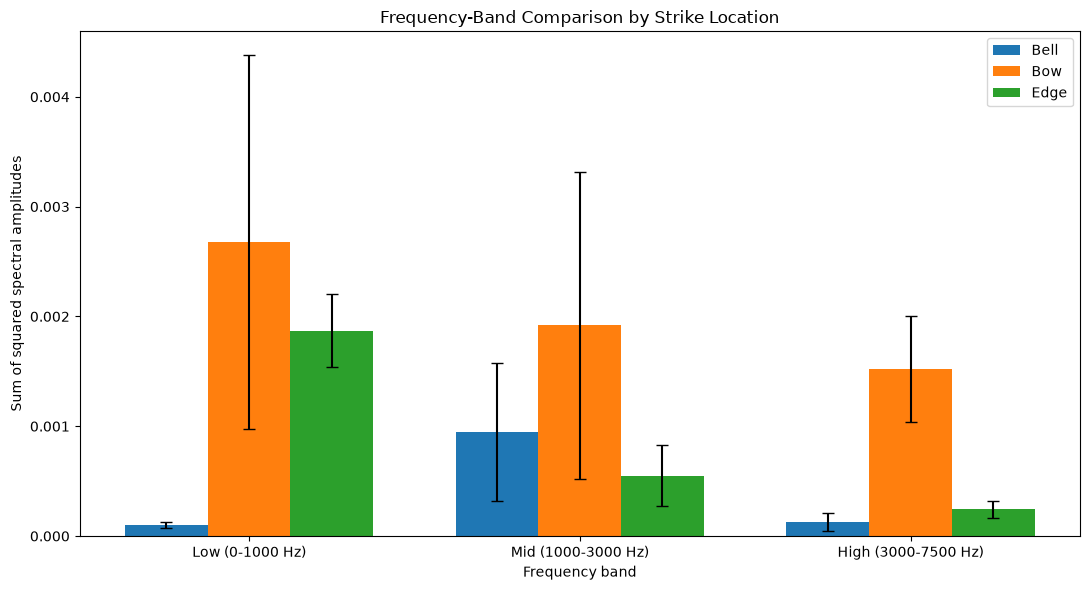

In [68]:
locations = list(band_values.keys())
band_names = list(bands.keys())

# Building the mean and standard deviation arrays.
means = []
stds = []

for location in locations:
    location_means = []
    location_stds = []

    for band in band_names:
        values = band_values[location][band]
        location_means.append(np.mean(values))
        location_stds.append(np.std(values, ddof=1))

    means.append(location_means)
    stds.append(location_stds)

means = np.array(means)
stds = np.array(stds)

x = np.arange(len(band_names))
width = 0.25

fig, ax = plt.subplots(figsize=(11, 6))

for i, location in enumerate(locations):
    offset = (i - (len(locations) - 1)/2)*width

    ax.bar(x + offset, means[i], width, yerr=stds[i], capsize=4, label=location)

ax.set_xlabel('Frequency band')
ax.set_ylabel('Sum of squared spectral amplitudes')
ax.set_title('Frequency-Band Comparison by Strike Location')
ax.set_xticks(x)
ax.set_xticklabels(band_names)
ax.legend()

fig.tight_layout()
plt.show()

## Observations of Frequency Band Comparisons

The frequency band comparison indicates that bow strikes generally produce the largest summed squared spectral amplitudes across the low, mid, and high frequency bands. The difference is particularly noticeable in the low-frequency band, where the bow strikes have a substantially larger mean than the bell strikes. Edge strikes also show greater low-frequency spectral amplitudes than bell strikes.

In the mid-frequency band, the bow strikes again have the largest mean, followed by the bell and edge strikes. In the high-frequency band, the bow strikes remain noticeably larger, while the bell and edge measurements are comparatively small.

The error bars indicate variation among repeated strikes. The bow strikes show substantial variability, especially in the low-frequency band, suggesting that their measured frequency was less consistent across trials. 

## Modeling the Cymbal's Amplitude Decay

To investigate how the cymbal's amplitude changes after a strike, the RMS envelope is calculated for each extracted segment using the same 10 millisecond window size used during event detection (see cells 8 and 9). The RMS envelopes are then averaged across the 20 trials for each location.

These averaged envelopes will be examined to determine whether an exponential decay model provides a reasonable approximation of the cymbal's response following impact. We'll plot the average envelopes below.

In [69]:
rms_segments = {}

for location, location_segments in segments.items():
    rms_segments[location] = []

    for segment in location_segments:
        # Dividing the segments into 10 millisecond windows.
        windows = segment.reshape(-1, window_size)

        # Calculate the RMS per window
        rms = np.sqrt(np.mean(windows**2, axis=1))

        rms_segments[location].append(rms)

    rms_segments[location] = np.array(rms_segments[location])

# We need a time axis relative to the beginning of each segment.
rms_times = (np.arange(rms_segments['Bell'].shape[1])*window_size/sample_rate)

# Calculating the average RMS envelope for each location.
mean_rms = {}
for location, values in rms_segments.items():
    mean_rms[location] = np.mean(values, axis=0)

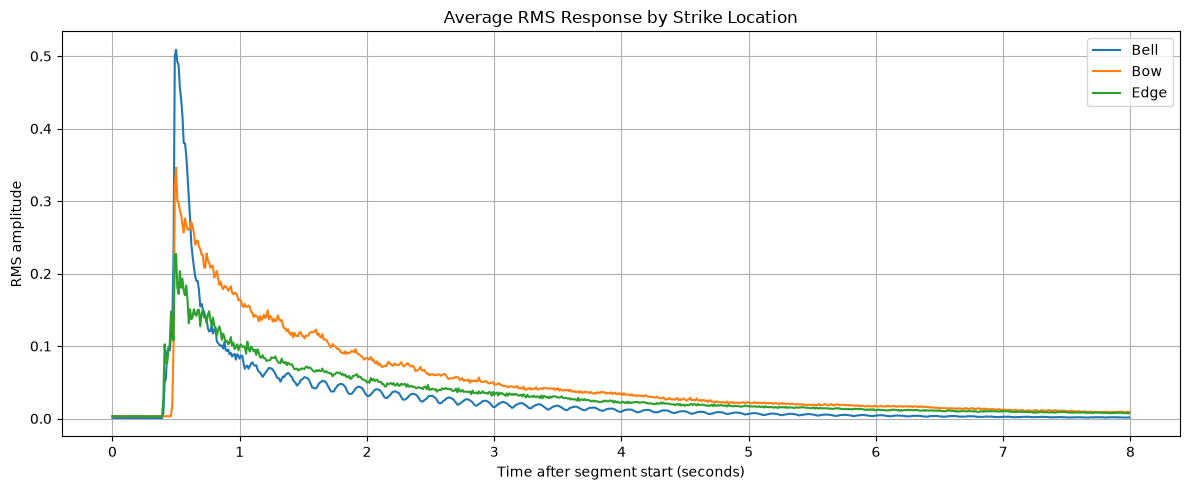

In [70]:
plt.figure(figsize=(12, 5))

for location, values in mean_rms.items():
    plt.plot(rms_times, values, label=location)

plt.xlabel('Time after segment start (seconds)')
plt.ylabel('RMS amplitude')
plt.title('Average RMS Response by Strike Location')

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## Exponential Decay Model

Let's fit an exponential decay model to the average RMS envelopes for each strike location. The fitting interval begins at the detected impact time and extends through the subsequent decay. The model estimates the initial amplitude, decay time constant, and background RMS level. These parameters allow us to compare the decay characteristics across each location.

In [71]:
from scipy.optimize import curve_fit

# Exponential decay model
def decay_model(t, A, tau, C):
    return A*np.exp(-t/tau) + C

# Fitting each location's average RMS response.
fit_results = {}

for location, values in mean_rms.items():

    # Same masking technique as used several times before. We need a time relative to the strike, approximately 0.5 seconds.
    mask = (rms_times >= 0.5) & (rms_times <= 4.0)
    t = rms_times[mask] - 0.5
    y = values[mask]

    # Initial estimates
    initial_guess = [np.max(y) - np.min(y), 1.0, np.min(y)]

    parameters, _ = curve_fit(decay_model, t, y, p0=initial_guess)

    A, tau, C = parameters

    # Now to calculate R-squared.
    predicted = decay_model(t, *parameters)
    ss_res = np.sum((y - predicted)**2)
    ss_tot = np.sum((y - np.mean(y))**2)
    r_squared = 1 - ss_res/ss_tot

    fit_results[location] = {'A': A, 'tau': tau, 'C': C, 'R_squared': r_squared}

    print(f'{location}: A = {A:.4f} \n tau = {tau:.4f} s \n C = {C:.4f} \n R-squared = {r_squared:.4f}')

Bell: A = 0.4780 
 tau = 0.1803 s 
 C = 0.0303 
 R-squared = 0.9563
Bow: A = 0.2476 
 tau = 0.8798 s 
 C = 0.0339 
 R-squared = 0.9861
Edge: A = 0.1497 
 tau = 0.7857 s 
 C = 0.0272 
 R-squared = 0.9747


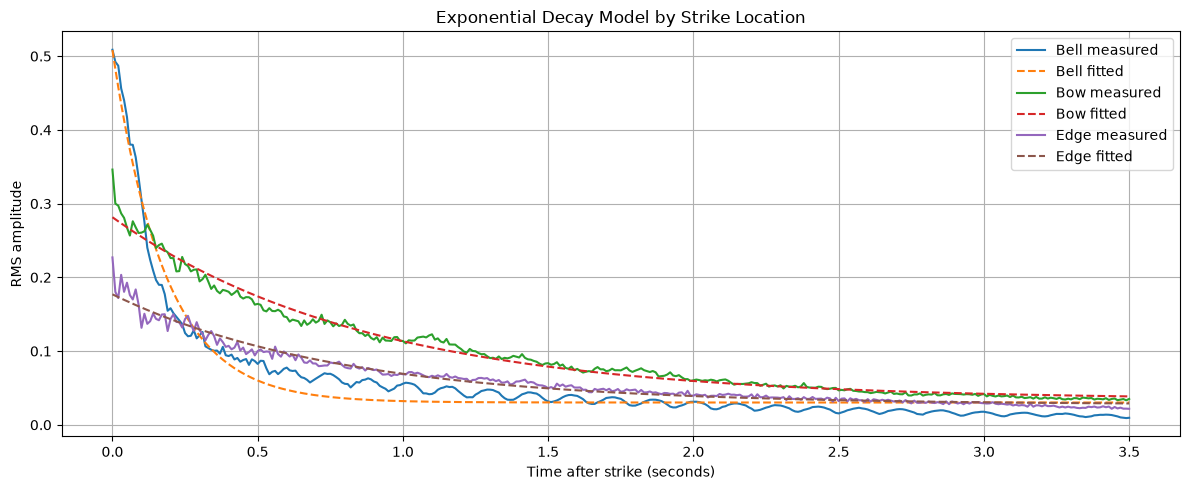

In [72]:
plt.figure(figsize=(12, 5))

mask = (rms_times >= 0.5) & (rms_times <= 4.0)
t = rms_times[mask] - 0.5

for location, values in mean_rms.items():
    plt.plot(t, values[mask], label=f'{location} measured')

    parameters = [
        fit_results[location]['A'],
        fit_results[location]['tau'],
        fit_results[location]['C']
    ]

    plt.plot(t, decay_model(t, *parameters), linestyle='--', label=f'{location} fitted')

plt.xlabel('Time after strike (seconds)')
plt.ylabel('RMS amplitude')
plt.title('Exponential Decay Model by Strike Location')

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## Exponential Decay Model Results

The graph compares the average RMS envelopes for the three strike locations with their corresponding exponential decay models. We get an expected decay in amplitude after the initial strike for each, but the rates differ significantly.

The bell exhibits the fastest decay with a time constant (\(\tau\)) of approximately 0.18 seconds. The bow decays more slowly, with a time constant of approxmiately 0.88 seconds, while the edge has an intermediate decay time of approximately 0.79 seconds. The fitted models have R-squared values above 0.95, indicating that the exponential function provides a reasonable approximation of the measured amplitude envelopes over the selected fitting interval.

These results suggest that strike location influences not only the frequency characteristics of the cymbal but also how its amplitude decreases over time.

## Final Thoughts

The results indicate that the location of a strike has a measurable effect on the frequency characteristics and amplitude decay of the cymbal. The bell produced a prominent frequency peak near 1750 Hz and exhibited the fasted amplitude decay. The bow showed a stronger low-frequency component near 500 Hz and the slowest decay, while the edge exhibited a different distribution of frequency components and an intermediate decay rate.
